In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Upload spam.csv
uploaded = files.upload()

df = pd.read_csv("spam.csv", encoding="latin-1")

# Keep the required columns
df = df[["v1", "v2"]].copy()
df.columns = ["label", "message"]

print("Original dataset shape:", df.shape)
print(df.head())

Saving spam_sms.csv to spam_sms.csv


FileNotFoundError: [Errno 2] No such file or directory: 'spam.csv'

In [2]:
from google.colab import files

uploaded = files.upload()

Saving spam_sms.csv to spam_sms (1).csv


In [3]:
import os

print(os.listdir("/content"))

['.config', 'spam_sms.csv', 'spam_sms (1).csv', 'sample_data']


In [4]:
import pandas as pd

df = pd.read_csv("/content/spam.csv", encoding="latin-1")

print("Dataset loaded successfully!")
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/spam.csv'

In [5]:
import pandas as pd
import numpy as np
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All packages imported successfully!")
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [6]:
uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving spam_sms.csv to spam_sms (2).csv
Uploaded files: ['spam_sms (2).csv']


In [7]:
csv_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise FileNotFoundError(
        "No CSV file uploaded. Please upload spam.csv."
    )

file_path = csv_files[0]

df = pd.read_csv(file_path, encoding="latin-1")

print("Dataset loaded successfully!")
print(df.head())
print("Original dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

Dataset loaded successfully!
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Original dataset shape: (5572, 2)
Column names: ['v1', 'v2']


In [8]:
if {"v1", "v2"}.issubset(df.columns):
    df = df[["v1", "v2"]].copy()
    df.columns = ["label", "message"]

elif {"label", "message"}.issubset(df.columns):
    df = df[["label", "message"]].copy()

else:
    raise ValueError(
        "Expected columns v1 and v2, or label and message."
    )

df = df.dropna(subset=["label", "message"])

df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[df["label"].isin(["ham", "spam"])]
df = df[df["message"] != ""]
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print(df.isnull().sum())
print(df["label"].value_counts())

Dataset shape after cleaning: (5158, 2)
label      0
message    0
dtype: int64
label
ham     4516
spam     642
Name: count, dtype: int64


In [9]:
class_counts = df["label"].value_counts()

samples_per_class = min(1000, class_counts.min())

df = (
    df.groupby("label", group_keys=False)
    .sample(n=samples_per_class, random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("Selected messages:", len(df))
print(df["label"].value_counts())

Selected messages: 1284
label
spam    642
ham     642
Name: count, dtype: int64


In [10]:
def clean_text(text):
    text = text.lower()

    text = re.sub(
        r"http\S+|www\.\S+",
        " url ",
        text
    )

    text = re.sub(
        r"[^a-z0-9\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


df["message"] = df["message"].apply(clean_text)

df = df[df["message"] != ""].reset_index(drop=True)

print(df.head())

  label                                            message
0  spam  you have won 1 000 cash or a 2 000 prize to cl...
1   ham                   have you always been saying welp
2  spam  fantasy football is back on your tv go to sky ...
3   ham           that said can you text him one more time
4  spam  no 1 polyphonic tone 4 ur mob every week just ...


In [11]:
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

X = df["message"].values
y = df["label"].values

print("Sample messages:")
print(X[:5])

print("Sample labels:")
print(y[:5])

Sample messages:
['you have won 1 000 cash or a 2 000 prize to claim call09050000327 t c rstm sw7 3ss 150ppm'
 'have you always been saying welp'
 'fantasy football is back on your tv go to sky gamestar on sky active and play 250k dream team scoring starts on saturday so register now sky opt out to 88088'
 'that said can you text him one more time'
 'no 1 polyphonic tone 4 ur mob every week just txt pt2 to 87575 1st tone free so get txtin now and tell ur friends 150p tone 16 reply hl 4info']
Sample labels:
[1 0 1 0 1]


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1027
Testing samples: 257


In [13]:
vocab_size = 10000
max_length = 100

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Original SMS:")
print(X_train[0])

print("Numerical sequence:")
print(X_train_seq[0])

Original SMS:
so what did the bank say about the money
Numerical sequence:
[38, 69, 201, 6, 813, 331, 136, 6, 258]


In [14]:
vocab_size = 10000
max_length = 100

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Original SMS:")
print(X_train[0])

print("Numerical sequence:")
print(X_train_seq[0])

Original SMS:
so what did the bank say about the money
Numerical sequence:
[38, 69, 201, 6, 813, 331, 136, 6, 258]


In [15]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train_pad.shape)
print("Testing data shape:", X_test_pad.shape)

Training data shape: (1027, 100)
Testing data shape: (257, 100)


In [16]:
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(
        64,
        dropout=0.2
    ),
    Dense(
        32,
        activation="relu"
    ),
    Dropout(0.3),
    Dense(
        1,
        activation="sigmoid"
    )
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.build(input_shape=(None, max_length))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")

NameError: name 'EarlyStopping' is not defined

In [18]:
from tensorflow.keras.callbacks import EarlyStopping

In [19]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")

Epoch 1/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 118ms/step - accuracy: 0.6675 - loss: 0.6565 - val_accuracy: 0.7621 - val_loss: 0.5325
Epoch 2/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.9440 - loss: 0.2932 - val_accuracy: 0.8981 - val_loss: 0.3679
Epoch 3/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.9854 - loss: 0.1148 - val_accuracy: 0.9175 - val_loss: 0.3281
Epoch 4/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.9878 - loss: 0.0730 - val_accuracy: 0.9320 - val_loss: 0.2476
Epoch 5/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.9939 - loss: 0.0386 - val_accuracy: 0.9223 - val_loss: 0.2770
Epoch 6/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.9963 - loss: 0.0216 - val_accuracy: 0.9175 - val_loss: 0.3470
Epoch 7/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 139ms/step - accuracy: 0.9988 - loss: 0.0129 - val_accuracy: 0.9175 - val_loss: 0.3666
Model training completed!


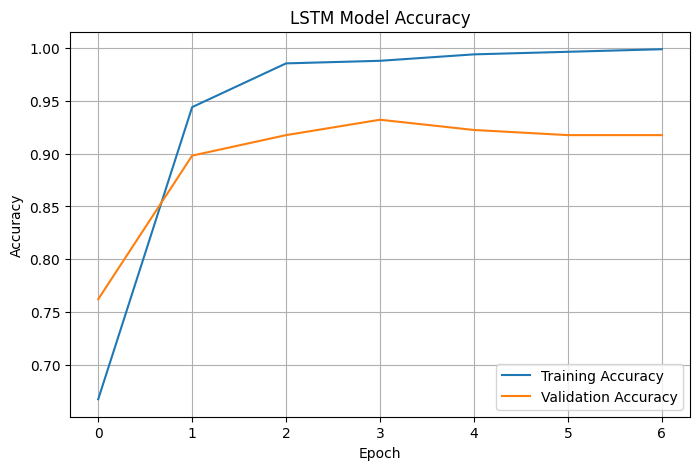

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
y_prob = model.predict(
    X_test_pad,
    verbose=0
).ravel()

y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, zero_division=0
)
recall = recall_score(
    y_test, y_pred, zero_division=0
)
f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("SMS SPAM DETECTION RESULTS")
print("--------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))

SMS SPAM DETECTION RESULTS
--------------------------
Accuracy  : 0.9572
Precision : 0.9835
Recall    : 0.9297
F1-score  : 0.9558

Classification Report:
              precision    recall  f1-score   support

         Ham       0.93      0.98      0.96       129
        Spam       0.98      0.93      0.96       128

    accuracy                           0.96       257
   macro avg       0.96      0.96      0.96       257
weighted avg       0.96      0.96      0.96       257



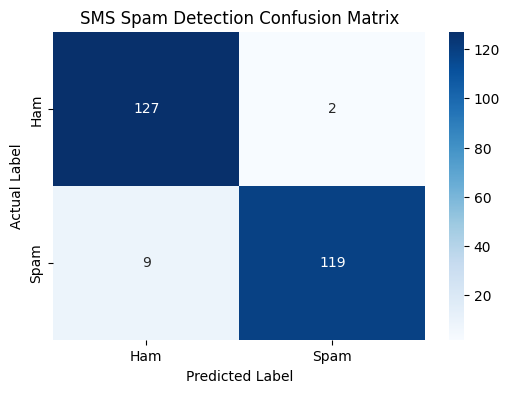

In [22]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection Confusion Matrix")

plt.show()

In [23]:
def predict_sms(message):
    cleaned_message = clean_text(message)

    sequence = tokenizer.texts_to_sequences(
        [cleaned_message]
    )

    padded_message = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded_message, verbose=0)[0][0]
    )

    if probability >= 0.5:
        prediction = "SPAM"
    else:
        prediction = "HAM"

    print("Message:", message)
    print("Prediction:", prediction)
    print(f"Spam probability: {probability:.2%}")
    print("-" * 45)

In [24]:
predict_sms(
    "Congratulations! You won a free cash prize. Claim now!"
)

predict_sms(
    "Hi, are we meeting at college tomorrow?"
)

predict_sms(
    "URGENT! You have won a free gift. Click now."
)

predict_sms(
    "Please call me when you reach home."
)

Message: Congratulations! You won a free cash prize. Claim now!
Prediction: SPAM
Spam probability: 94.46%
---------------------------------------------
Message: Hi, are we meeting at college tomorrow?
Prediction: HAM
Spam probability: 2.34%
---------------------------------------------
Message: URGENT! You have won a free gift. Click now.
Prediction: SPAM
Spam probability: 88.58%
---------------------------------------------
Message: Please call me when you reach home.
Prediction: HAM
Spam probability: 38.36%
---------------------------------------------


In [25]:
model.save("sms_spam_lstm.keras")

print("Model saved successfully!")

Model saved successfully!


In [26]:
files.download("sms_spam_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

def test_sms(message):
    cleaned_message = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned_message])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    prediction = "SPAM" if probability >= 0.5 else "HAM"

    print("SMS Message:", message)
    print("Prediction:", prediction)
    print(f"Spam Probability: {probability * 100:.2f}%")
    print("-" * 50)

Enter an SMS message: My Native 
SMS Message: My Native 
Prediction: HAM
Spam Probability: 22.11%
--------------------------------------------------


In [31]:
message = input("Enter an SMS message: ")

test_sms(message)

Enter an SMS message: My Native Is Coimbatore
SMS Message: My Native Is Coimbatore
Prediction: HAM
Spam Probability: 14.60%
--------------------------------------------------


In [32]:
message = input("Enter an SMS message: ")

test_sms(message)

Enter an SMS message: hi You Won A Samsung S26 Ultra and iPhone 18 Pro Max
SMS Message: hi You Won A Samsung S26 Ultra and iPhone 18 Pro Max
Prediction: SPAM
Spam Probability: 63.42%
--------------------------------------------------


In [28]:
message = input("Enter an SMS message: ")

test_sms(message)

Enter an SMS message: You Won a Free Gift !
SMS Message: You Won a Free Gift !
Prediction: SPAM
Spam Probability: 68.40%
--------------------------------------------------


In [29]:
message = input("Enter an SMS message: ")

test_sms(message)

Enter an SMS message: happy birthday alan
SMS Message: happy birthday alan
Prediction: HAM
Spam Probability: 17.55%
--------------------------------------------------
